¿cuál es la frecuencia de la serie? La frecuencia es mensual, por un periodo de 200 meses, equivalente a 16 años y 8 meses

¿En qué unidad está medida (tasa en %, índice u otra)? está medida en índice

¿Desde qué fecha hay datos? hay datos desde enero del 2010

# Índice de precios de cereales (ONU)
Serie mensual 2010–2026 descargada de la Organización de las Naciones Unidas para la Alimentación y la Agricultura (F019.PPBA.INP.46B.M).

**Antes de ejecutar:**
1. `Entorno de ejecución → Cambiar tipo de entorno de ejecución → R`.
2. Abre el panel de archivos (ícono de carpeta a la izquierda) y sube `EI_PROD_BAS_AL (Cereales).xlsx`.
3. `Entorno de ejecución → Ejecutar todas`.

## 1. Paquetes

In [ ]:
# Colab (R) ya trae tidyverse; solo instala lo que falte
paquetes <- c("readxl", "dplyr", "ggplot2", "scales", "tidyr")
faltan <- paquetes[!paquetes %in% rownames(installed.packages())]
if (length(faltan) > 0) install.packages(faltan)

suppressPackageStartupMessages({
  library(readxl); library(dplyr); library(ggplot2); library(scales); library(tidyr)
})

## 2. Lectura y limpieza de datos
La hoja `Cuadro` trae el título en la fila 1 y los encabezados en la fila 3, por eso se saltan 2 filas.

Se eligió la fórmula de variación porcentual interanual ya que la serie analizada es un índice de precios y no una tasa o porcentaje. Los números índices miden cambios relativos de magnitud, no proporciones, por lo tanto la única forma correcta de medir el crecimiento interanual de los precios de los cereales es con la tasa de variación porcentual.

In [ ]:
archivo <- list.files(c("/content", "."), pattern = "\\.xlsx$", full.names = TRUE)[1]
if (is.na(archivo)) stop("No encontré el .xlsx. Súbelo desde el panel de archivos (ícono de carpeta).")
cat("Leyendo:", archivo, "\n")

raw <- read_excel(archivo, sheet = "Cuadro", skip = 2)

df <- raw |>
  select(fecha = 1, indice = 2) |>
  mutate(fecha = as.Date(fecha), indice = as.numeric(indice)) |>
  filter(!is.na(fecha), !is.na(indice)) |>
  arrange(fecha) |>
  mutate(
    anio      = as.integer(format(fecha, "%Y")),
    mes       = as.integer(format(fecha, "%m")),
    media_12m = as.numeric(stats::filter(indice, rep(1/12, 12), sides = 1)),  # promedio móvil 12 meses
   var_12m = (indice / lag(indice, 12) - 1) * 100
  )

cat("Observaciones:", nrow(df), "\n")
summary(df$indice)
tail(df)

Leyendo: ./EI_PROD_BAS_AL (Cereales).xlsx 
Observaciones: 200 


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  85.96   98.02  111.40  115.21  130.33  173.52 

fecha,indice,anio,mes,media_12m,var_12m
<date>,<dbl>,<int>,<int>,<dbl>,<dbl>
2026-03-01,110.4203,2026,3,107.2671,0.6624960
2026-04-01,111.3228,2026,4,107.3015,0.3715434
2026-05-01,114.1674,2026,5,107.7348,4.7718198
2026-06-01,110.0000,2026,6,107.9625,2.5476018
2026-07-01,113.8000,2026,7,108.5745,6.8978585
2026-08-01,116.3000,2026,8,109.4622,10.0838307


## 3. Estilo común para los gráficos

In [ ]:
# Crea un vector con las abreviaturas de los 12 meses en español
meses_es  <- c("Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic")
# Crea una función que convierte una fecha en una etiqueta tipo "Ago 2026"
etq_fecha <- function(x) paste(meses_es[as.integer(format(x, "%m"))], format(x, "%Y"))
# Crea una función que formatea números
num_es    <- function(x) number(x, accuracy = 0.1, decimal.mark = ",")

col_principal <- "#1F4E79"   # azul
col_acento    <- "#E07B39"   # naranjo

# estilo visual común
tema <- theme_minimal(base_size = 13) +
  theme(
    plot.title         = element_text(face = "bold", size = 20, colour = "#1A1A1A"),
    plot.subtitle      = element_text(colour = "#555555", margin = margin(b = 12)),
    plot.caption       = element_text(colour = "#888888", size = 9, hjust = 0),
    plot.title.position = "plot", plot.caption.position = "plot",
    panel.grid.minor   = element_blank(),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(colour = "#E5E5E5"),
    legend.position    = "top", legend.justification = "left",
    plot.background    = element_rect(fill = "white", colour = NA),
    plot.margin        = margin(15, 20, 10, 15)
  )

fuente <- "Fuente: Base de Datos Estadísticos del Banco Central de Chile / FAO. Serie F019.PPBA.INP.46B.M."

## 4. Evolución del Índice de Precios de Cereales
Serie mensual, promedio móvil de 12 meses, período de pandemia sombreado y marcas en el máximo, el mínimo y el último dato.

Warning message in max(ids, na.rm = TRUE):
“no non-missing arguments to max; returning -Inf”


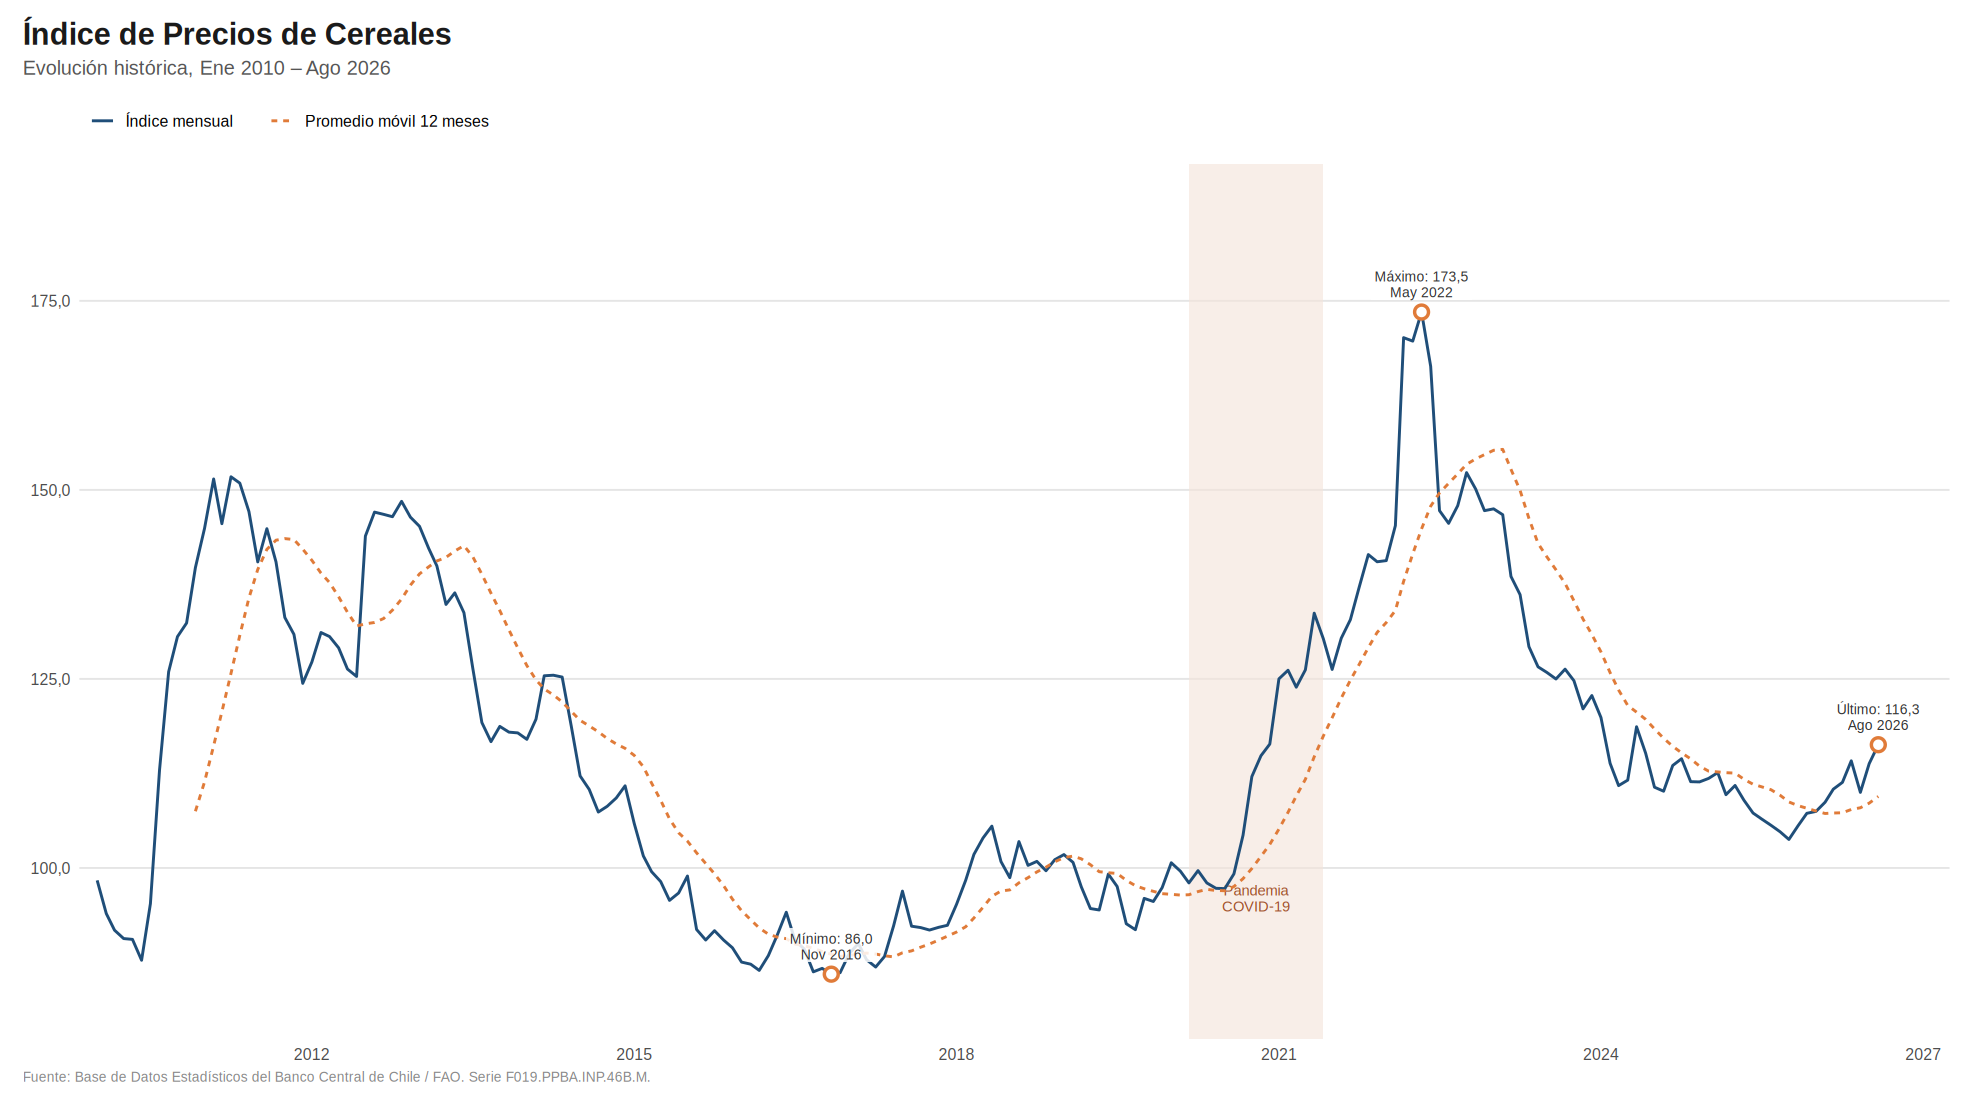

In [ ]:
# Serie mensual, promedio móvil de 12 meses, período de pandemia sombreado y marcas en el máximo, el mínimo y el último dato.
options(repr.plot.width = 18, repr.plot.height = 10, repr.plot.res = 110)

# arma una tabla llamada hitos con el máximo, el mínimo y el último dato del índice.
hitos <- bind_rows(
  df |> slice_max(indice, n = 1) |> mutate(txt = paste0("Máximo: ", num_es(indice), "\n", etq_fecha(fecha))),
  df |> slice_min(indice, n = 1) |> mutate(txt = paste0("Mínimo: ", num_es(indice), "\n", etq_fecha(fecha))),
  df |> slice_tail(n = 1)        |> mutate(txt = paste0("Último: ", num_es(indice), "\n", etq_fecha(fecha)))
)

# construye el gráfico y lo guarda como g1
g1 <- ggplot(df, aes(fecha)) +
  annotate("rect", xmin = as.Date("2020-03-01"), xmax = as.Date("2022-05-01"),
           ymin = -Inf, ymax = Inf, fill = "#F3E3D8", alpha = .6) +
  annotate("text", x = as.Date("2021-04-01"), y = min(df$indice, na.rm = TRUE) + 8, label = "Pandemia\nCOVID-19",
           size = 3.4, colour = "#A0522D", lineheight = .9) +
  geom_area(aes(y = indice), fill = col_principal, alpha = .07) +
  geom_line(aes(y = indice, colour = "Índice mensual"), linewidth = .9) +
  geom_line(aes(y = media_12m, colour = "Promedio móvil 12 meses"),
            linewidth = .9, linetype = "22", na.rm = TRUE) +
  geom_point(data = hitos, aes(y = indice), size = 3.2, colour = col_acento,
             fill = "white", shape = 21, stroke = 1.6) +
  geom_label(data = hitos, aes(y = indice, label = txt), size = 3.2, vjust = -0.35,
             linewidth = 0, fill = alpha("white", .85), colour = "#333333", lineheight = .95) +
  scale_colour_manual(NULL, values = c("Índice mensual" = col_principal,
                                       "Promedio móvil 12 meses" = col_acento)) +
  scale_x_date(date_breaks = "3 years", date_labels = "%Y",
               expand = expansion(mult = c(.01, .04))) +
  scale_y_continuous(labels = num_es,
                     limits = c(min(df$indice, na.rm = TRUE) * 0.9, max(df$indice, na.rm = TRUE) * 1.1),
                     expand = expansion(mult = c(0, .02))) +
  labs(title = "Índice de Precios de Cereales",
       subtitle = paste0("Evolución histórica, ",
                         etq_fecha(min(df$fecha)), " – ", etq_fecha(max(df$fecha))),
       x = NULL, y = NULL, caption = fuente) +
  tema
g1

## 5. Mapa de calor por año y mes
Permite ver de un vistazo los años altos y bajos y el patrón estacional.

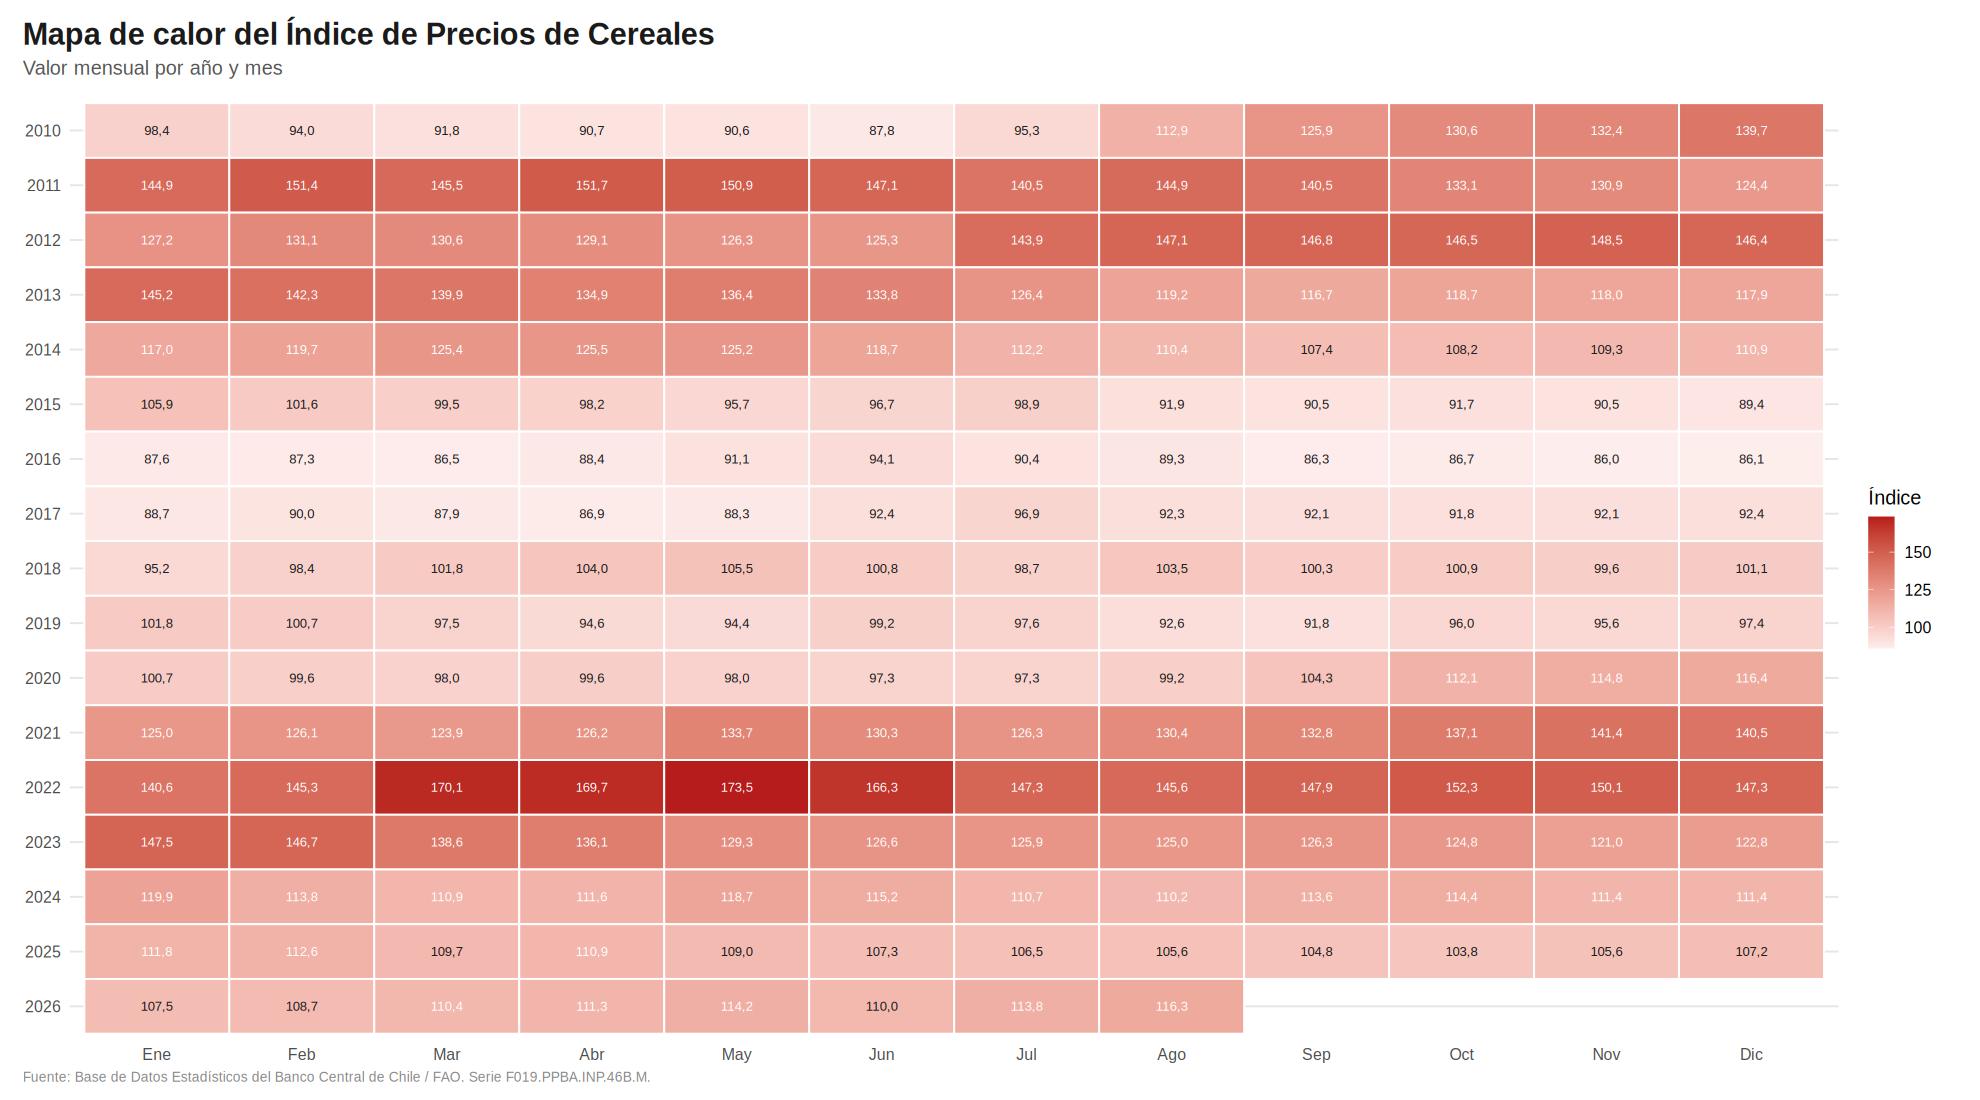

In [ ]:
# define el tamaño y la resolución con que Colab muestra los gráficos en el notebook
options(repr.plot.width = 18, repr.plot.height = 10)

# construye el mapa de calor y lo guarda como g2
g2 <- ggplot(df, aes(factor(mes, levels = 1:12, labels = meses_es),
                     factor(anio, levels = rev(sort(unique(anio)))),
                     fill = indice)) +
  geom_tile(colour = "white", linewidth = .6) +
  geom_text(aes(label = num_es(indice), colour = indice > 110), size = 3, show.legend = FALSE) +
  scale_colour_manual(values = c(`TRUE` = "white", `FALSE` = "#1A1A1A")) +
  scale_fill_gradient(low = "#FDEDEC", high = "#B71C1C", name = "Índice") +
  labs(title = "Mapa de calor del Índice de Precios de Cereales",
       subtitle = "Valor mensual por año y mes", x = NULL, y = NULL, caption = fuente) +
  tema + theme(panel.grid = element_blank(), legend.position = "right")

g2

## 6. Variación en 12 meses
Variación porcentual del índice respecto del mismo mes del año anterior.

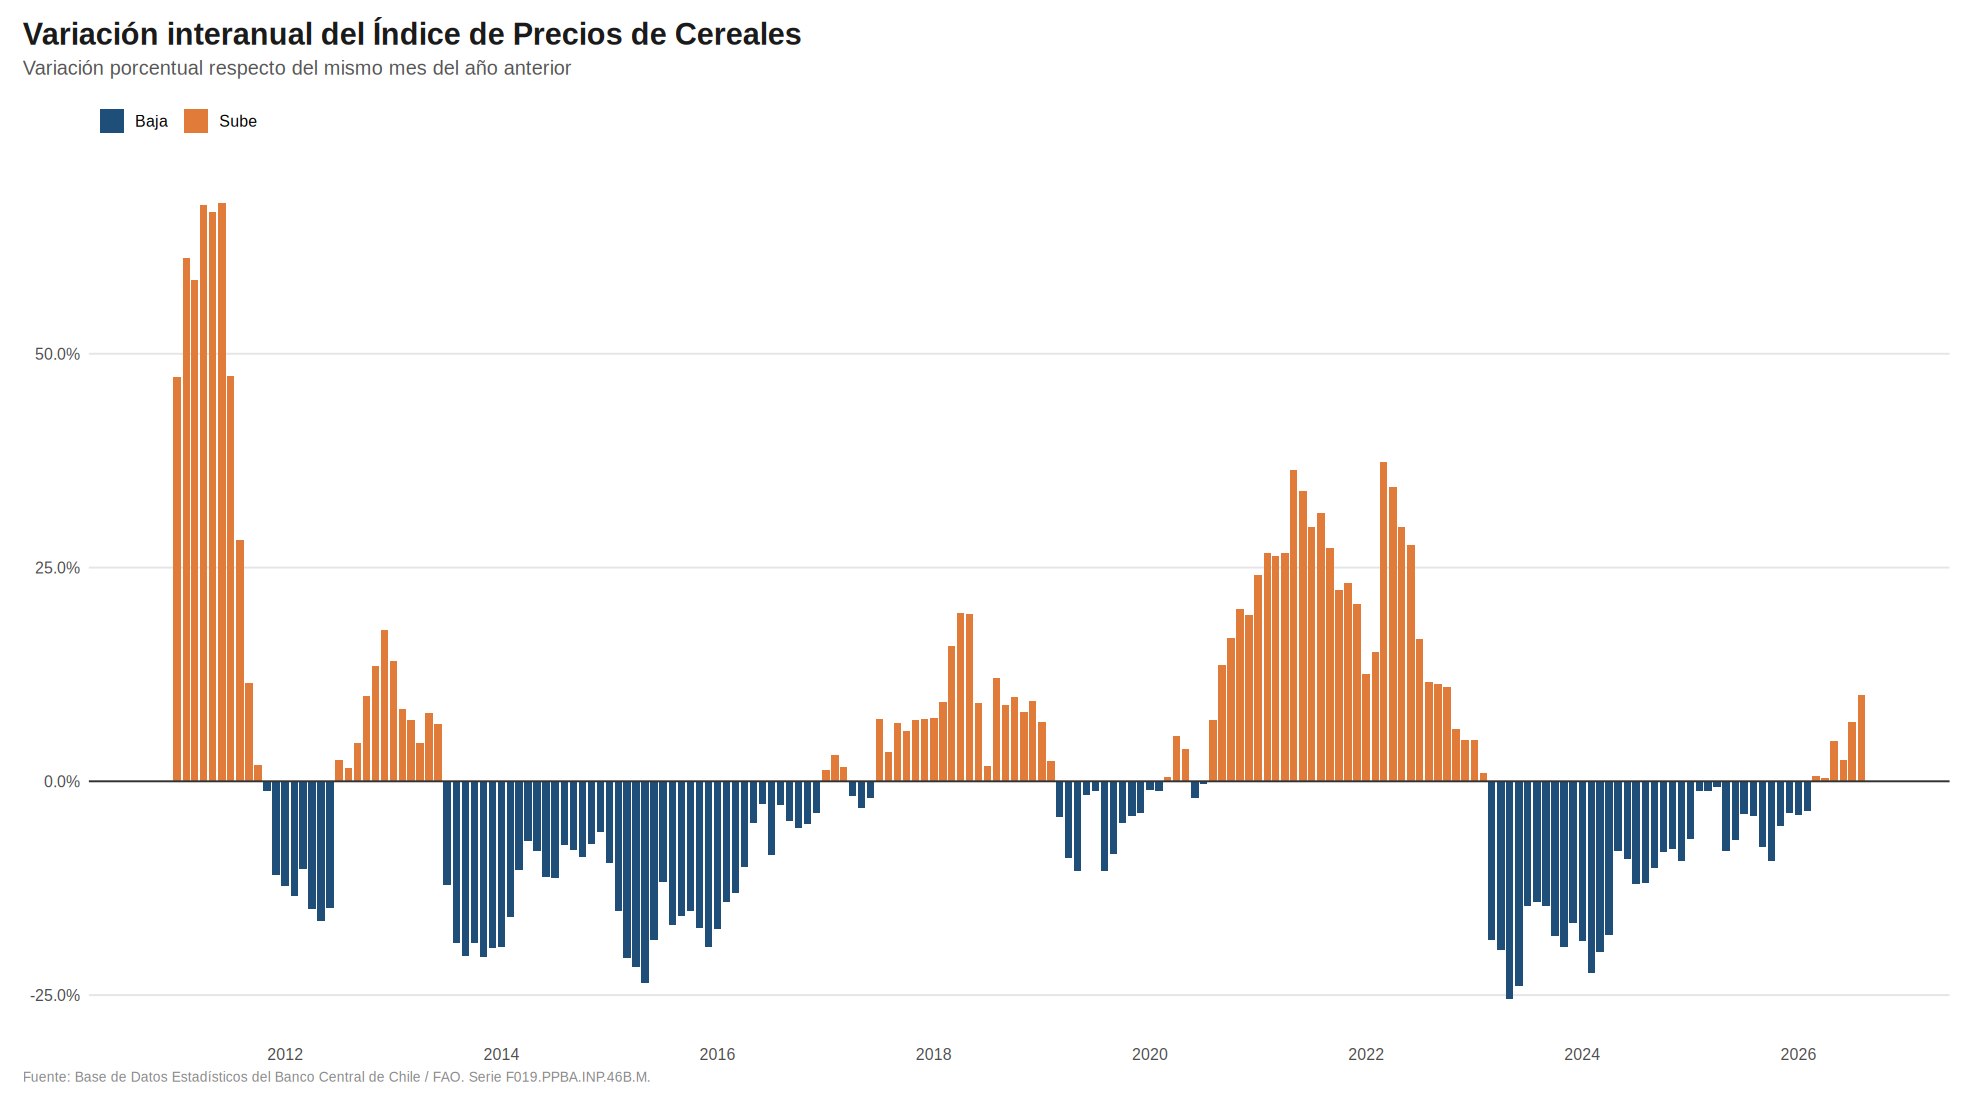

In [ ]:
# define el tamaño y la resolución con que Colab muestra los gráficos en el notebook
options(repr.plot.width = 18, repr.plot.height = 10)

# construye el gráfico de barras de la variación en 12 meses y lo guarda como g3
g3 <- df |>
  filter(!is.na(var_12m)) |>
  ggplot(aes(fecha, var_12m, fill = var_12m > 0)) +
  geom_col(width = 25) +
  geom_hline(yintercept = 0, colour = "#333333") +
  scale_fill_manual(NULL, values = c(`TRUE` = col_acento, `FALSE` = col_principal),
                    labels = c(`TRUE` = "Sube", `FALSE` = "Baja")) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y") +
  scale_y_continuous(labels = label_number(accuracy = 0.1, suffix = "%")) +
  labs(title = "Variación interanual del Índice de Precios de Cereales",
       subtitle = "Variación porcentual respecto del mismo mes del año anterior",
       x = NULL, y = NULL, caption = fuente) +
  tema

g3

## 7. Guardar los gráficos en PNG
Quedan en el panel de archivos; clic derecho → Descargar.

In [ ]:
ggsave("cereales_serie.png",        g1, width = 12, height = 6.5, dpi = 300)
ggsave("cereales_mapa_calor.png",   g2, width = 11, height = 8,   dpi = 300)
ggsave("cereales_variacion12m.png", g3, width = 12, height = 5.5, dpi = 300)

list.files(pattern = "\\.png$")

Warning message in max(ids, na.rm = TRUE):
“no non-missing arguments to max; returning -Inf”


[1] "cereales_mapa_calor.png"       "cereales_serie.png"           
[3] "cereales_variacion12m.png"     "desocupacion_mapa_calor.png"  
[5] "desocupacion_serie.png"        "desocupacion_variacion12m.png"

El análisis del Índice de Precios de Cereales (enero de 2010 a agosto de 2026) evidencia una marcada volatilidad asociada a choques de oferta, condiciones climáticas y disrupciones en el comercio agrícola global. El registro más reciente, correspondiente a agosto de 2026, alcanza los 116,3 puntos, ubicándose ligeramente por encima del promedio histórico del período analizado (115,2 puntos) y reflejando una moderada recuperación tras las caídas observadas entre 2023 y 2025.

Al observar los extremos de la serie, el mínimo histórico se registró en noviembre de 2016 con 86,0 puntos, en un contexto de holgura en los inventarios mundiales y cosechas récord. En contraste, el máximo histórico se alcanzó en mayo de 2022 con 173,5 puntos, impulsado por los cuellos de botella logísticos posteriores a la pandemia de COVID-19 y el estallido del conflicto entre Rusia y Ucrania, países clave en la exportación global de granos.

Por su parte, el mapa de calor muestra que la estacionalidad es débil; el comportamiento de la serie está dominado por ciclos de varios años, con precios altos en 2011–2013 y 2021–2023 y bajos entre 2015 y 2019. Finalmente, el gráfico de variación interanual confirma que, tras las fuertes alzas de 2021–2022 (superiores al 35% interanual) y el posterior proceso de desinflación agrícola entre 2023 y 2025, la serie retorna en 2026 a variaciones interanuales positivas moderadas, sugiriendo una estabilización de los precios internacionales.